# Ojo en órbita

Estudiamos si podemos descubrir usos del suelo con imágenes de satélite. Trabajamos con **8.000 parches RGB de 64 × 64 píxeles, 800 por clase**, seleccionados de [EuroSAT](https://github.com/phelber/EuroSAT).


## Dataset EuroSAT RGB

Descargamos el [subconjunto EuroSAT RGB en formato ZIP](https://upm365-my.sharepoint.com/:u:/g/personal/anton_pogromskyy_alumnos_upm_es/IQCVHas6nvyzQ5q_0426Mu43AUznmqcDQGyoeKBE_wm5yg8?e=rYR1dK) y lo extraemos en `data/EuroSAT_RGB_800/`. Cada JPG tiene un TIFF del mismo parche en el subconjunto multiespectral. Podremos usarlo más adelante para probar qué aporta la banda de infrarrojo cercano B08.


In [1]:
from pathlib import Path
import subprocess
from tempfile import TemporaryDirectory
from zipfile import BadZipFile, ZipFile, is_zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import kurtosis, skew

In [2]:
RGB_DATASET_URL = (
    "https://upm365-my.sharepoint.com/:u:/g/personal/"
    "anton_pogromskyy_alumnos_upm_es/"
    "IQCVHas6nvyzQ5q_0426Mu43AUznmqcDQGyoeKBE_wm5yg8?e=rYR1dK&download=1"
)
EMBEDDINGS_URL = "https://upm365-my.sharepoint.com/:u:/g/personal/anton_pogromskyy_alumnos_upm_es/IQCNndBnJCd1RaWCgisxMQwTAfoenZTg5pFc5_1RbkJLixM?e=THLtSs&download=1"

DATA_DIR = Path("data")
RGB_DIR = DATA_DIR / "EuroSAT_RGB_800"
RGB_ARCHIVE_PATH = DATA_DIR / "EuroSAT_RGB_800.zip"

DATA_DIR.mkdir(parents=True, exist_ok=True)

### Características precalculadas

Al inicio comprobamos los CSV de características y los pares de embeddings e índices en `results/`. Si falta algún archivo, descargamos el ZIP de OneDrive para recuperarlo. Cada sección calcula sus características si siguen faltando.


In [3]:
features_dir = Path("results")
features_dir.mkdir(exist_ok=True)
spectral_path = features_dir / "spectral_features.csv"
haralick_path = features_dir / "haralick_features.csv"
lbp_path = features_dir / "lbp_features.csv"
embedding_models = ("resnet50", "clip")


def embedding_files(model):
    return (features_dir / f"{model}_embeddings.npy", features_dir / f"{model}_index.csv")


def embeddings_available(model):
    return all(path.is_file() for path in embedding_files(model))


feature_groups = [
    (spectral_path,),
    (haralick_path,),
    (lbp_path,),
    *(embedding_files(model) for model in embedding_models),
]


missing_groups = [paths for paths in feature_groups if not all(path.is_file() for path in paths)]
if missing_groups and EMBEDDINGS_URL:
    try:
        with TemporaryDirectory(dir=features_dir) as temp_dir:
            temp_dir = Path(temp_dir)
            downloaded_archive = temp_dir / "features_eurosat.zip"
            subprocess.run(
                ["curl", "-fsSL", "-b", "", "--connect-timeout", "15", "--max-time", "300",
                 EMBEDDINGS_URL, "-o", str(downloaded_archive)],
                check=True,
            )

            with ZipFile(downloaded_archive) as archive:
                members = set(archive.namelist())
                for paths in missing_groups:
                    if all(path.as_posix() in members for path in paths):
                        for path in paths:
                            archive.extract(path.as_posix(), temp_dir)
                        for path in paths:
                            (temp_dir / path).replace(path)
    except (BadZipFile, OSError, subprocess.CalledProcessError) as error:
        print(f"No se pudieron recuperar las características precalculadas: {error}")


### Descarga y extracción

Si ya hay 8.000 JPG extraídos, los reutilizamos. En caso contrario, extraemos el ZIP local o lo descargamos desde OneDrive si hace falta.


In [4]:
rgb_paths = sorted(RGB_DIR.glob("*/*.jpg"))

if len(rgb_paths) != 8000:
    if not is_zipfile(RGB_ARCHIVE_PATH):
        subprocess.run(
            ["curl", "-fsSL", "-b", "", RGB_DATASET_URL, "-o", str(RGB_ARCHIVE_PATH)],
            check=True,
        )

    with ZipFile(RGB_ARCHIVE_PATH) as archive:
        archive.extractall(DATA_DIR)

    rgb_paths = sorted(RGB_DIR.glob("*/*.jpg"))

if len(rgb_paths) != 8000:
    raise ValueError(f"Expected 8,000 JPG files, found {len(rgb_paths):,}.")

print(f"Dataset ready: {len(rgb_paths):,} images.")


Dataset ready: 8,000 images.


## Apartado A. Extracción de características

Calcularemos una fila de características por parche. Empezamos con los cuatro momentos de cada canal RGB de una imagen para comprobar el procedimiento. Después lo aplicaremos a todo el subconjunto y añadiremos los momentos en HSV y Lab.


In [5]:
image_path = rgb_paths[0]

with Image.open(image_path) as image:
    rgb = np.asarray(image.convert("RGB"), dtype=np.float64)

print("Image:", image_path.name)
print("RGB shape:", rgb.shape)
print(f"Value range: {rgb.min():.0f} to {rgb.max():.0f}")


Image: AnnualCrop_1.jpg
RGB shape: (64, 64, 3)
Value range: 82 to 204


In [6]:
# Arrange pixels as rows and RGB channels as columns.
pixels = rgb.reshape(-1, 3)
print("Pixels shape:", pixels.shape)

summary_rgb = pd.DataFrame(
    {
        "mean": pixels.mean(axis=0),
        "std": pixels.std(axis=0, ddof=0),
        "skewness": skew(pixels, axis=0, bias=True),
        "excess_kurtosis": kurtosis(pixels, axis=0, fisher=True, bias=True),
    },
    index=["R", "G", "B"],
)

display(summary_rgb.round(3))


Pixels shape: (4096, 3)


,mean,std,skewness,excess_kurtosis
R,109.109,15.522,2.545,8.976
G,97.438,9.320,2.435,8.546
B,104.854,6.950,2.081,7.067


En `AnnualCrop_1.jpg`, el rojo tiene la mayor media (109,11) y la mayor desviación típica (15,52). El azul tiene la menor dispersión (6,95). Los tres canales muestran asimetría positiva y exceso de curtosis positivo. En los histogramas se observa la cola hacia intensidades altas. Usamos la escala original de los JPG, de 0 a 255, y los mismos intervalos en los tres canales.


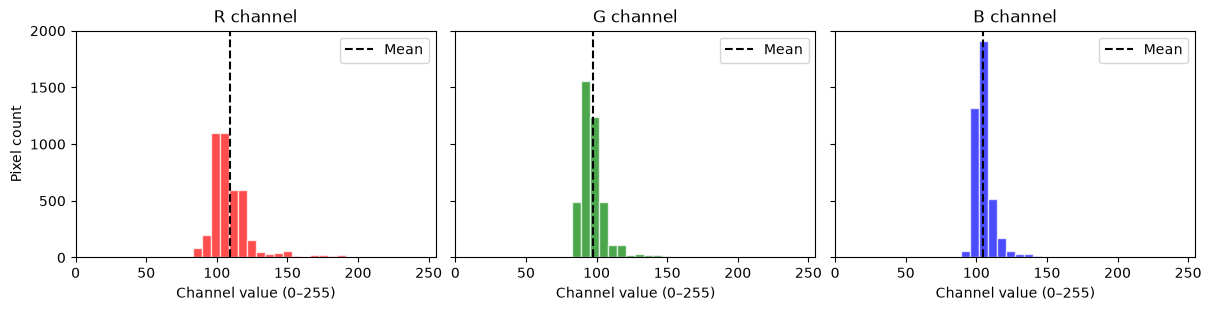

In [7]:
channel_names = ["R", "G", "B"]
channel_colors = ["red", "green", "blue"]
bin_edges = np.linspace(0, 255, 41)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True, layout="constrained")

for channel_index, (ax, name, color) in enumerate(
    zip(axes, channel_names, channel_colors)
):
    values = pixels[:, channel_index]
    ax.hist(values, bins=bin_edges, color=color, alpha=0.7, edgecolor="white")
    ax.axvline(values.mean(), color="black", linestyle="--", label="Mean")

    ax.set_title(f"{name} channel")
    ax.set_xlabel("Channel value (0–255)")
    ax.set_xlim(0, 255)
    ax.legend()

axes[0].set_ylabel("Pixel count")
plt.show()

### Características RGB

In [8]:
def color_moments(image, color_space, channel_names):
    pixels = image.reshape(-1, len(channel_names))

    statistics = {
        "mean": pixels.mean(axis=0),
        "std": pixels.std(axis=0, ddof=0),
        "skewness": skew(pixels, axis=0, bias=True),
        "excess_kurtosis": kurtosis(pixels, axis=0, fisher=True, bias=True),
    }

    features = {}
    for channel_index, channel_name in enumerate(channel_names):
        for statistic_name, values in statistics.items():
            column_name = f"{color_space}_{channel_name}_{statistic_name}"
            features[column_name] = values[channel_index]

    return features


def select_color_space(features, prefix):
    columns = [column for column in features if column.startswith(f"{prefix}_")]
    return features[["class_name", "patch_id", *columns]]


In [9]:
spectral_features = pd.read_csv(spectral_path) if spectral_path.is_file() else None

if spectral_features is not None:
    rgb_features = select_color_space(spectral_features, "RGB")
else:
    rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float64)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }

        rgb_moments = color_moments(rgb_image, "RGB", ("R", "G", "B"))
        row.update(rgb_moments)
        rows.append(row)

    rgb_features = pd.DataFrame(rows)

print("Table shape:", rgb_features.shape)
display(rgb_features.head().round(3))

Table shape: (8000, 14)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,RGB_B_mean,RGB_B_std,RGB_B_skewness,RGB_B_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,104.854,6.950,2.081,7.067
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,99.659,12.001,0.778,-0.822
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,99.320,12.315,1.788,2.036
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,129.450,19.415,0.459,-0.755
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,122.260,32.277,3.011,9.123


### Características HSV

In [10]:
if spectral_features is not None:
    hsv_features = select_color_space(spectral_features, "HSV")
else:
    from matplotlib.colors import rgb_to_hsv

    hsv_rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float64)

        # convert RGB values from [0, 255] to [0, 1]
        hsv_image = rgb_to_hsv(rgb_image / 255.0)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem
        }

        hsv_moments = color_moments(hsv_image, "HSV", ("H", "S", "V"))
        row.update(hsv_moments)
        hsv_rows.append(row)

    hsv_features = pd.DataFrame(hsv_rows)
display(hsv_features.head().round(3))

,class_name,patch_id,HSV_H_mean,HSV_H_std,HSV_H_skewness,HSV_H_excess_kurtosis,HSV_S_mean,HSV_S_std,HSV_S_skewness,HSV_S_excess_kurtosis,HSV_V_mean,HSV_V_std,HSV_V_skewness,HSV_V_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,0.826,0.171,-3.549,13.778,0.113,0.040,0.972,3.443,0.431,0.058,2.868,10.538
1,AnnualCrop,AnnualCrop_1002,0.549,0.073,1.410,5.644,0.326,0.161,-0.735,-0.905,0.392,0.047,0.767,-0.813
2,AnnualCrop,AnnualCrop_1005,0.474,0.183,-1.539,2.651,0.270,0.088,-1.108,0.342,0.406,0.081,2.052,3.005
3,AnnualCrop,AnnualCrop_1009,0.213,0.315,1.669,1.302,0.220,0.118,0.130,-1.327,0.675,0.199,0.332,-1.235
4,AnnualCrop,AnnualCrop_1010,0.156,0.213,1.504,1.437,0.191,0.101,-0.311,-0.992,0.578,0.169,0.938,0.414


In [11]:
color_features = rgb_features.merge(
    hsv_features,
    on = ["class_name", "patch_id"],
    how = "left"
)

print("Table shape:", color_features.shape)
display(color_features.head().round(3))

Table shape: (8000, 26)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,...,HSV_H_skewness,HSV_H_excess_kurtosis,HSV_S_mean,HSV_S_std,HSV_S_skewness,HSV_S_excess_kurtosis,HSV_V_mean,HSV_V_std,HSV_V_skewness,HSV_V_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,...,-3.549,13.778,0.113,0.040,0.972,3.443,0.431,0.058,2.868,10.538
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,...,1.410,5.644,0.326,0.161,-0.735,-0.905,0.392,0.047,0.767,-0.813
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,...,-1.539,2.651,0.270,0.088,-1.108,0.342,0.406,0.081,2.052,3.005
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,...,1.669,1.302,0.220,0.118,0.130,-1.327,0.675,0.199,0.332,-1.235
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,...,1.504,1.437,0.191,0.101,-0.311,-0.992,0.578,0.169,0.938,0.414


### Características LAB

In [12]:
if spectral_features is not None:
    lab_features = select_color_space(spectral_features, "Lab")
else:
    import cv2

    lab_rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float32)

        lab_image = cv2.cvtColor(rgb_image / 255.0, cv2.COLOR_RGB2LAB)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        lab_moments = color_moments(lab_image.astype(np.float32), "Lab", ("L", "a", "b"))
        row.update(lab_moments)
        lab_rows.append(row)

    lab_features = pd.DataFrame(lab_rows)
display(lab_features.head().round(3))

,class_name,patch_id,Lab_L_mean,Lab_L_std,Lab_L_skewness,Lab_L_excess_kurtosis,Lab_a_mean,Lab_a_std,Lab_a_skewness,Lab_a_excess_kurtosis,Lab_b_mean,Lab_b_std,Lab_b_skewness,Lab_b_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,42.462,4.216,2.520,8.713,6.133,2.747,-0.033,2.692,-2.478,2.614,2.239,7.862
1,AnnualCrop,AnnualCrop_1002,38.549,5.883,0.678,-0.873,-8.191,5.241,0.876,-0.389,-5.386,2.158,0.034,-0.416
2,AnnualCrop,AnnualCrop_1005,39.550,7.427,1.587,1.460,-5.278,6.316,1.021,0.878,-3.655,4.090,1.116,0.237
3,AnnualCrop,AnnualCrop_1009,60.685,12.877,0.253,-1.276,9.976,10.542,0.267,-1.172,10.122,8.215,0.158,-1.464
4,AnnualCrop,AnnualCrop_1010,54.277,13.785,1.773,3.556,5.474,9.170,0.010,-0.941,5.058,5.797,0.580,0.720


In [13]:
if spectral_features is None:
    spectral_features = color_features.merge(
        lab_features,
        on=["class_name", "patch_id"],
        how="left",
    )
    spectral_features.to_csv(spectral_path, index=False)

print("Table shape:", spectral_features.shape)
display(spectral_features.head().round(3))

Table shape: (8000, 38)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,...,Lab_L_skewness,Lab_L_excess_kurtosis,Lab_a_mean,Lab_a_std,Lab_a_skewness,Lab_a_excess_kurtosis,Lab_b_mean,Lab_b_std,Lab_b_skewness,Lab_b_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,...,2.520,8.713,6.133,2.747,-0.033,2.692,-2.478,2.614,2.239,7.862
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,...,0.678,-0.873,-8.191,5.241,0.876,-0.389,-5.386,2.158,0.034,-0.416
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,...,1.587,1.460,-5.278,6.316,1.021,0.878,-3.655,4.090,1.116,0.237
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,...,0.253,-1.276,9.976,10.542,0.267,-1.172,10.122,8.215,0.158,-1.464
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,...,1.773,3.556,5.474,9.170,0.010,-0.941,5.058,5.797,0.580,0.720


### Características de Textura: Características de Haralick 

In [14]:
if haralick_path.is_file():
    haralick_features = pd.read_csv(haralick_path)
else:
    from skimage.feature import graycomatrix, graycoprops
    from tqdm.auto import tqdm

    distances = [1, 3, 5]
    angles = np.deg2rad([0, 45, 90, 135])
    properties = ["entropy", "homogeneity", "contrast", "dissimilarity", "correlation"]


    def haralick_features_for_image(gray_image):
        glcm = graycomatrix(
            gray_image,
            distances=distances,
            angles=angles,
            levels=256,
            symmetric=False,
        )

        features = {}

        for property_name in properties:
            mean_by_distance = graycoprops(glcm, property_name).mean(axis=1)

            for distance, value in zip(distances, mean_by_distance):
                features[f"GLCM_{property_name}_d{distance}"] = value

        return features


    haralick_rows = []

    for image_path in tqdm(rgb_paths, desc="Extracting Haralick features"):
        with Image.open(image_path) as image:
            gray_image = np.array(image.convert("L"))

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        row.update(haralick_features_for_image(gray_image))
        haralick_rows.append(row)

    haralick_features = pd.DataFrame(haralick_rows)
    haralick_features.to_csv(haralick_path, index=False)

print("Table shape:", haralick_features.shape)
display(haralick_features.head().round(3))

Table shape: (8000, 17)


,class_name,patch_id,GLCM_entropy_d1,GLCM_entropy_d3,GLCM_entropy_d5,GLCM_homogeneity_d1,GLCM_homogeneity_d3,GLCM_homogeneity_d5,GLCM_contrast_d1,GLCM_contrast_d3,GLCM_contrast_d5,GLCM_dissimilarity_d1,GLCM_dissimilarity_d3,GLCM_dissimilarity_d5,GLCM_correlation_d1,GLCM_correlation_d3,GLCM_correlation_d5
0,AnnualCrop,AnnualCrop_1,5.506,5.882,6.065,0.434,0.314,0.246,23.040,67.241,109.360,2.402,4.116,5.605,0.897,0.678,0.416
1,AnnualCrop,AnnualCrop_1002,5.843,6.251,6.474,0.439,0.317,0.241,31.427,96.551,166.059,2.930,5.529,7.972,0.938,0.809,0.667
2,AnnualCrop,AnnualCrop_1005,5.873,6.322,6.555,0.430,0.297,0.213,69.554,261.501,528.766,3.916,8.279,13.274,0.908,0.656,0.309
3,AnnualCrop,AnnualCrop_1009,7.001,7.295,7.417,0.306,0.205,0.152,69.964,243.960,514.885,4.485,8.504,13.497,0.970,0.894,0.773
4,AnnualCrop,AnnualCrop_1010,6.886,7.175,7.315,0.289,0.192,0.139,96.962,301.595,631.552,5.158,9.318,14.213,0.965,0.891,0.767


### Características de Textura: Características de LBP (Local Binary Patterns)

In [15]:
if lbp_path.is_file():
    lbp_features = pd.read_csv(lbp_path)
else:
    from skimage.feature import local_binary_pattern
    from tqdm.auto import tqdm

    num_neighbors = 8
    radius = 1
    lbp_rows = []

    for image_path in tqdm(rgb_paths, desc="Extracting LBP features"):
        with Image.open(image_path) as image:
            gray_image = np.array(image.convert("L"))

        lbp_codes = local_binary_pattern(
            gray_image, P=num_neighbors, R=radius, method="uniform"
        )

        # Keep only pixels whose neighborhood fits inside the image.
        interior_codes = lbp_codes[1:-1, 1:-1].astype(int)
        counts = np.bincount(interior_codes.ravel(), minlength=num_neighbors + 2)
        frequencies = counts / counts.sum()

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        for code, frequency in enumerate(frequencies):
            row[f"LBP_{code}"] = frequency
        lbp_rows.append(row)

    lbp_features = pd.DataFrame(lbp_rows)
    lbp_features.to_csv(lbp_path, index=False)

print("Table shape:", lbp_features.shape)
display(lbp_features.head().round(3))

Table shape: (8000, 12)


,class_name,patch_id,LBP_0,LBP_1,LBP_2,LBP_3,LBP_4,LBP_5,LBP_6,LBP_7,LBP_8,LBP_9
0,AnnualCrop,AnnualCrop_1,0.039,0.075,0.037,0.102,0.131,0.152,0.099,0.091,0.140,0.133
1,AnnualCrop,AnnualCrop_1002,0.037,0.068,0.032,0.079,0.200,0.130,0.078,0.087,0.154,0.136
2,AnnualCrop,AnnualCrop_1005,0.033,0.064,0.029,0.081,0.213,0.136,0.091,0.086,0.143,0.125
3,AnnualCrop,AnnualCrop_1009,0.040,0.079,0.041,0.102,0.196,0.142,0.080,0.090,0.097,0.133
4,AnnualCrop,AnnualCrop_1010,0.031,0.084,0.044,0.107,0.176,0.159,0.069,0.094,0.108,0.126


In [16]:
if any(not embeddings_available(model) for model in embedding_models):
    import torch
    from tqdm.auto import tqdm

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

    print("Dispositivo para la extracción:", device)


### Embeddings de CNN ResNet50

In [17]:
resnet50_path, resnet50_index_path = embedding_files("resnet50")

if embeddings_available("resnet50"):
    resnet50_embeddings = np.load(resnet50_path)
    resnet50_index = pd.read_csv(resnet50_index_path)
    print("Embeddings de ResNet50 cargados desde results/.")
else:
    from torchvision.models import ResNet50_Weights, resnet50

    weights = ResNet50_Weights.IMAGENET1K_V2
    preprocess = weights.transforms()

    feature_extractor = resnet50(weights=weights)
    feature_extractor.fc = torch.nn.Identity()
    feature_extractor = feature_extractor.to(device)
    feature_extractor.eval()

    batch_size = 32
    embedding_batches = []

    batch_starts = range(0, len(rgb_paths), batch_size)

    with torch.inference_mode():
        for start in tqdm(batch_starts, desc="Extracting ResNet50 embeddings"):
            batch_paths = rgb_paths[start : start + batch_size]
            image_tensors = []

            for image_path in batch_paths:
                with Image.open(image_path) as image:
                    image_tensors.append(preprocess(image.convert("RGB")))

            input_batch = torch.stack(image_tensors).to(device)
            batch_embeddings = feature_extractor(input_batch)
            embedding_batches.append(batch_embeddings.cpu().numpy())

    resnet50_embeddings = np.concatenate(embedding_batches, axis=0)

    resnet50_index = pd.DataFrame({
        "class_name": [path.parent.name for path in rgb_paths],
        "patch_id": [path.stem for path in rgb_paths],
    })

    assert len(resnet50_embeddings) == len(resnet50_index)
    np.save(resnet50_path, resnet50_embeddings)
    resnet50_index.to_csv(resnet50_index_path, index=False)

print("Dimensiones de los embeddings de ResNet50:", resnet50_embeddings.shape)

Embeddings de ResNet50 cargados desde results/.
Dimensiones de los embeddings de ResNet50: (8000, 2048)


### Embeddings de CNN CLIP ViT-B/32

In [18]:
clip_path, clip_index_path = embedding_files("clip")

if embeddings_available("clip"):
    clip_embeddings = np.load(clip_path)
    clip_index = pd.read_csv(clip_index_path)
    print("Embeddings de CLIP cargados desde results/.")
else:
    from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection

    clip_model_id = "openai/clip-vit-base-patch32"

    clip_processor = CLIPImageProcessor.from_pretrained(clip_model_id)
    clip_model = CLIPVisionModelWithProjection.from_pretrained(clip_model_id)
    clip_model = clip_model.to(device)
    clip_model.eval()

    clip_batch_size = 32
    clip_batches = []

    batch_starts = range(0, len(rgb_paths), clip_batch_size)

    with torch.inference_mode():
        for start in tqdm(batch_starts, desc="Extracting CLIP embeddings"):
            batch_paths = rgb_paths[start : start + clip_batch_size]
            images = []

            for image_path in batch_paths:
                with Image.open(image_path) as image:
                    images.append(image.convert("RGB"))

            inputs = clip_processor(images=images, return_tensors="pt")
            pixel_values = inputs["pixel_values"].to(device)

            batch_embeddings = clip_model(pixel_values=pixel_values).image_embeds
            batch_embeddings = torch.nn.functional.normalize(batch_embeddings, dim=1)

            clip_batches.append(batch_embeddings.cpu().numpy())

    clip_embeddings = np.concatenate(clip_batches, axis=0)

    clip_index = pd.DataFrame({
        "class_name": [path.parent.name for path in rgb_paths],
        "patch_id": [path.stem for path in rgb_paths],
    })

    assert clip_embeddings.shape == (len(clip_index), 512)
    np.save(clip_path, clip_embeddings)
    clip_index.to_csv(clip_index_path, index=False)

print("Dimensiones de los embeddings de CLIP:", clip_embeddings.shape)

Embeddings de CLIP cargados desde results/.
Dimensiones de los embeddings de CLIP: (8000, 512)


## Apartado B. Anotación semántica con CLIP

En este apartado queremos saber si CLIP puede reconocer el uso del suelo de un parche de EuroSAT a partir de una descripción en inglés y hasta qué punto cambia el resultado según cómo la redactemos. Reutilizamos los 8.000 embeddings de imagen del apartado A y comprobamos que tenemos una fila por parche en el índice. Aplicamos el modelo preentrenado sin ajustar sus pesos con EuroSAT y reservamos la etiqueta oficial de cada parche para comprobar el acierto después de predecir.


In [19]:
assert clip_embeddings.shape[0] == len(clip_index), (
    "Debe haber una fila en clip_index por cada embedding."
)

class_names = sorted(clip_index["class_name"].unique())

print("Forma de la matriz de embeddings:", clip_embeddings.shape)
print("Número de clases:", len(class_names))
print("Clases:", class_names)

display(clip_index.head())

Forma de la matriz de embeddings: (8000, 512)
Número de clases: 10
Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


,class_name,patch_id
0,AnnualCrop,AnnualCrop_1
1,AnnualCrop,AnnualCrop_1002
2,AnnualCrop,AnnualCrop_1005
3,AnnualCrop,AnnualCrop_1009
4,AnnualCrop,AnnualCrop_1010


### Dos formas de describir las clases

En V1 usamos el nombre de cada una de las diez clases dentro de la plantilla *a satellite photo of…*. Por ejemplo, la frase que representa a **River** es *a satellite photo of a river*. Usamos esta redacción como referencia para medir qué pasa cuando damos a CLIP una descripción visual más concreta.


In [20]:
class_phrases_v1 = {
    "AnnualCrop": "annual crop fields",
    "Forest": "a forest",
    "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "a highway",
    "Industrial": "an industrial area",
    "Pasture": "a pasture",
    "PermanentCrop": "permanent crop fields",
    "Residential": "a residential area",
    "River": "a river",
    "SeaLake": "a sea or a lake",
}

prompts_v1 = [
    f"a satellite photo of {class_phrases_v1[class_name]}"
    for class_name in class_names
]

for class_name, prompt in zip(class_names, prompts_v1):
    print(f"{class_name:24} → {prompt}")

AnnualCrop               → a satellite photo of annual crop fields
Forest                   → a satellite photo of a forest
HerbaceousVegetation     → a satellite photo of herbaceous vegetation
Highway                  → a satellite photo of a highway
Industrial               → a satellite photo of an industrial area
Pasture                  → a satellite photo of a pasture
PermanentCrop            → a satellite photo of permanent crop fields
Residential              → a satellite photo of a residential area
River                    → a satellite photo of a river
SeaLake                  → a satellite photo of a sea or a lake


En la V2 original mantenemos la referencia a las imágenes de satélite y describimos rasgos que podrían verse desde arriba. Para **River** hablamos de un cauce sinuoso bordeado de vegetación, mientras que para **Industrial** mencionamos naves rectangulares y superficies pavimentadas. Usamos los mismos parches en ambas pruebas para que la comparación refleje el cambio de redacción.


In [21]:
class_phrases_v2 = {
    "AnnualCrop": "rectangular fields with low crops and patches of bare soil",
    "Forest": "a dense canopy of trees with an irregular texture",
    "HerbaceousVegetation": "an open area with low wild vegetation and scattered bare patches",
    "Highway": "a wide paved road with parallel lanes crossing the landscape",
    "Industrial": "large rectangular warehouses surrounded by paved lots",
    "Pasture": "an open grassy field with a smooth texture and visible field boundaries",
    "PermanentCrop": "an orchard or vineyard with plants arranged in regular rows",
    "Residential": "a neighborhood with closely spaced houses along small streets",
    "River": "a winding water channel bordered by vegetation",
    "SeaLake": "a broad expanse of open water with few visible features on its surface",
}

prompts_v2 = [
    f"a satellite photo of {class_phrases_v2[class_name]}"
    for class_name in class_names
]

for class_name, prompt in zip(class_names, prompts_v2):
    print(f"{class_name:24} → {prompt}")

AnnualCrop               → a satellite photo of rectangular fields with low crops and patches of bare soil
Forest                   → a satellite photo of a dense canopy of trees with an irregular texture
HerbaceousVegetation     → a satellite photo of an open area with low wild vegetation and scattered bare patches
Highway                  → a satellite photo of a wide paved road with parallel lanes crossing the landscape
Industrial               → a satellite photo of large rectangular warehouses surrounded by paved lots
Pasture                  → a satellite photo of an open grassy field with a smooth texture and visible field boundaries
PermanentCrop            → a satellite photo of an orchard or vineyard with plants arranged in regular rows
Residential              → a satellite photo of a neighborhood with closely spaced houses along small streets
River                    → a satellite photo of a winding water channel bordered by vegetation
SeaLake                  → a satellite

### De los prompts a las predicciones

Convertimos cada frase en un vector de 512 valores con el codificador de texto del mismo CLIP ViT-B/32 que usamos para las imágenes y normalizamos cada vector para que tenga longitud uno. Como usamos diez frases por versión, obtenemos una matriz de embeddings de texto de 10 filas y 512 columnas.


In [22]:
import torch
from transformers import AutoTokenizer, CLIPTextModelWithProjection

clip_checkpoint = "openai/clip-vit-base-patch32"

tokenizer = AutoTokenizer.from_pretrained(clip_checkpoint)
text_encoder = CLIPTextModelWithProjection.from_pretrained(clip_checkpoint)
text_encoder.eval()


def encode_prompts(prompts):
    inputs = tokenizer(prompts, padding=True, return_tensors="pt")

    with torch.inference_mode():
        vectors = text_encoder(**inputs).text_embeds
        vectors = torch.nn.functional.normalize(vectors, dim=1)

    return vectors.cpu().numpy()


text_embeddings_v1 = encode_prompts(prompts_v1)
text_embeddings_v2 = encode_prompts(prompts_v2)

print("Versión 1:", text_embeddings_v1.shape)
print("Versión 2:", text_embeddings_v2.shape)

/Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1121 19:49:13.997000 3314 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 50116.93it/s]
[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UN

Versión 1: (10, 512)
Versión 2: (10, 512)


In [23]:
scores_v1 = clip_embeddings @ text_embeddings_v1.T
scores_v2 = clip_embeddings @ text_embeddings_v2.T

print("Puntuaciones de la versión 1:", scores_v1.shape)
print("Puntuaciones de la versión 2:", scores_v2.shape)

image_idx = 0
image_info = clip_index.iloc[image_idx]

print("Parche:", image_info["patch_id"])
print("Etiqueta real:", image_info["class_name"])

example_scores = pd.DataFrame({
    "Clase": class_names,
    "Versión 1": scores_v1[image_idx],
    "Versión 2": scores_v2[image_idx],
})

display(example_scores.round(4))

Puntuaciones de la versión 1: (8000, 10)
Puntuaciones de la versión 2: (8000, 10)
Parche: AnnualCrop_1
Etiqueta real: AnnualCrop


,Clase,Versión 1,Versión 2
0,AnnualCrop,0.3577,0.3582
1,Forest,0.3097,0.3027
2,HerbaceousVegetation,0.3207,0.3060
3,Highway,0.3016,0.3025
4,Industrial,0.3251,0.3145
5,Pasture,0.3269,0.3240
6,PermanentCrop,0.3536,0.3348
7,Residential,0.3267,0.3103
8,River,0.2746,0.2988
9,SeaLake,0.2862,0.3004


Al multiplicar los embeddings de imagen por los de texto transpuestos, calculamos la similitud coseno entre cada parche y cada frase, ya que ambos tipos de vectores tienen longitud uno. El resultado es una matriz de puntuaciones de 8.000 filas y diez columnas por versión, con un parche por fila y una clase por columna.

En el primer parche, **AnnualCrop_1**, las dos versiones dan la puntuación más alta a **AnnualCrop** y coinciden con la etiqueta oficial. En V1, **PermanentCrop** queda muy cerca, con 0,3536 frente a 0,3577. Buscamos de forma automática la puntuación máxima en cada fila y asignamos al parche la clase que corresponde a esa columna.


In [24]:
classes = np.asarray(class_names)

predictions = clip_index.copy()
predictions["pred_v1"] = classes[scores_v1.argmax(axis=1)]
predictions["pred_v2"] = classes[scores_v2.argmax(axis=1)]

print("Parches etiquetados:", len(predictions))
display(predictions.head())

Parches etiquetados: 8000


,class_name,patch_id,pred_v1,pred_v2
0,AnnualCrop,AnnualCrop_1,AnnualCrop,AnnualCrop
1,AnnualCrop,AnnualCrop_1002,AnnualCrop,AnnualCrop
2,AnnualCrop,AnnualCrop_1005,AnnualCrop,AnnualCrop
3,AnnualCrop,AnnualCrop_1009,AnnualCrop,AnnualCrop
4,AnnualCrop,AnnualCrop_1010,Residential,Residential


### Exactitud global y aciertos por clase

Primero comparamos las predicciones con las etiquetas oficiales y dividimos el número de aciertos entre los 8.000 parches. Después miramos la exactitud dentro de cada clase para localizar las diferencias que explican el resultado global.


In [25]:
correct_v1 = predictions["pred_v1"] == predictions["class_name"]
correct_v2 = predictions["pred_v2"] == predictions["class_name"]

accuracy_summary = pd.DataFrame({
    "Prompts": ["V1 (Nombre de la clase)", "V2 (Descripción visual)"],
    "Aciertos": [correct_v1.sum(), correct_v2.sum()],
    "Exactitud (%)": [100 * correct_v1.mean(), 100 * correct_v2.mean()],
})

display(accuracy_summary.round(2))

,Prompts,Aciertos,Exactitud (%)
0,V1 (Nombre de la clase),3335,41.69
1,V2 (Descripción visual),3650,45.62


Con V1 acertamos 3.335 parches y con la V2 original acertamos 3.650, por lo que la exactitud sube del **41,69 % al 45,62 %**. La gráfica por clase nos permite ver que la mejora se reparte de forma desigual, ya que cada barra mide qué porcentaje de los 800 parches de esa clase reconocimos correctamente.


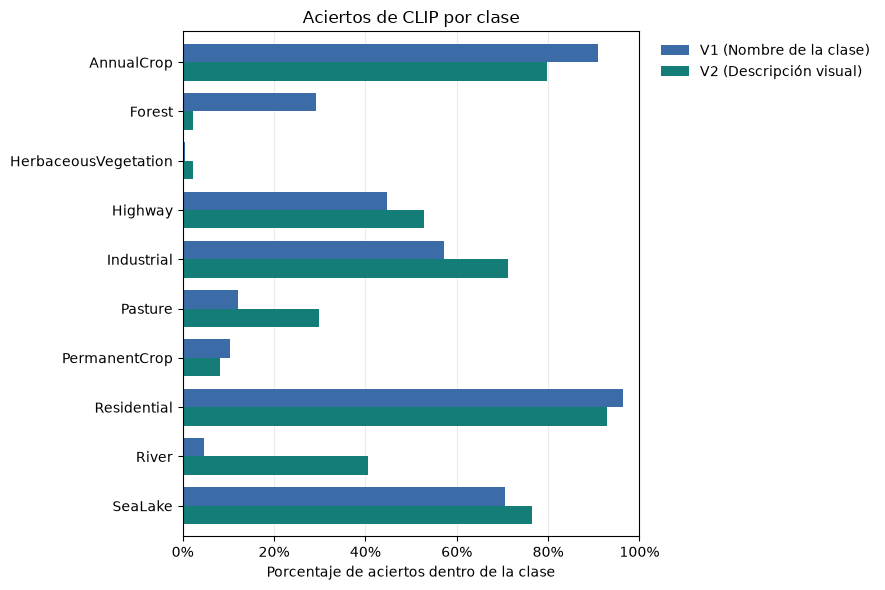

In [26]:
from matplotlib.ticker import PercentFormatter

class_results = pd.DataFrame({
    "Clase": predictions["class_name"],
    "V1 (Nombre de la clase)": correct_v1,
    "V2 (Descripción visual)": correct_v2,
})

accuracy_by_class = (
    class_results.groupby("Clase")
    .mean()
    .mul(100)
    .reindex(class_names)
)

ax = accuracy_by_class.plot.barh(
    figsize=(9, 6),
    color=["#3B6CA8", "#147D78"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Aciertos de CLIP por clase")
ax.set_xlabel("Porcentaje de aciertos dentro de la clase")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

plt.tight_layout()
plt.show()

### Qué clases confunde CLIP

En las matrices leemos la clase oficial en la fila y la predicción en la columna. Cada fila se expresa como porcentaje de los parches de esa clase, de modo que la diagonal coincide con los aciertos de la gráfica anterior y las demás celdas indican qué etiqueta eligió CLIP cuando falló.


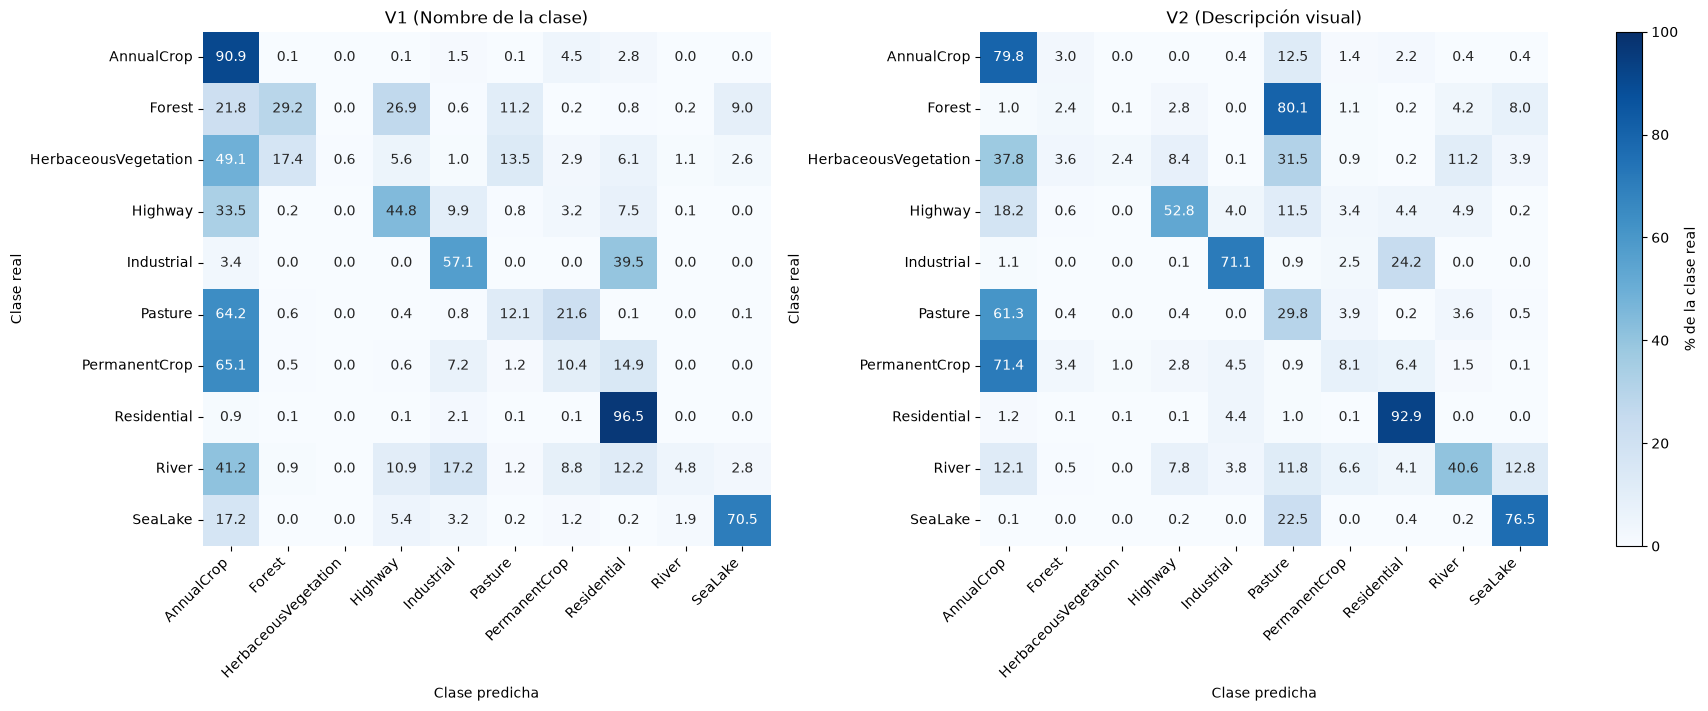

In [27]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

matrix_v1 = confusion_matrix(
    predictions["class_name"],
    predictions["pred_v1"],
    labels=class_names,
    normalize="true",
) * 100

matrix_v2 = confusion_matrix(
    predictions["class_name"],
    predictions["pred_v2"],
    labels=class_names,
    normalize="true",
) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout="constrained")

for ax, matrix, title in zip(
    axes,
    [matrix_v1, matrix_v2],
    ["V1 (Nombre de la clase)", "V2 (Descripción visual)"],
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="Clase predicha", ylabel="Clase real")
    ax.tick_params(axis="y", labelrotation=0)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.colorbar(axes[0].collections[0], ax=axes, label="% de la clase real")
plt.show()

La descripción visual ayuda en **River**, donde los aciertos pasan del 4,8 % al 40,6 %, y en **Industrial**, donde suben del 57,1 % al 71,1 %. En **Forest** ocurre lo contrario, ya que la V2 original clasifica como **Pasture** al 80,1 % de los bosques. Para entender qué puede haber detrás de estas confusiones, seleccionamos de forma reproducible un parche de cada uno de cinco tipos de fallo de la V2 original y mostramos también la predicción de V1.

### Análisis de cinco fallos


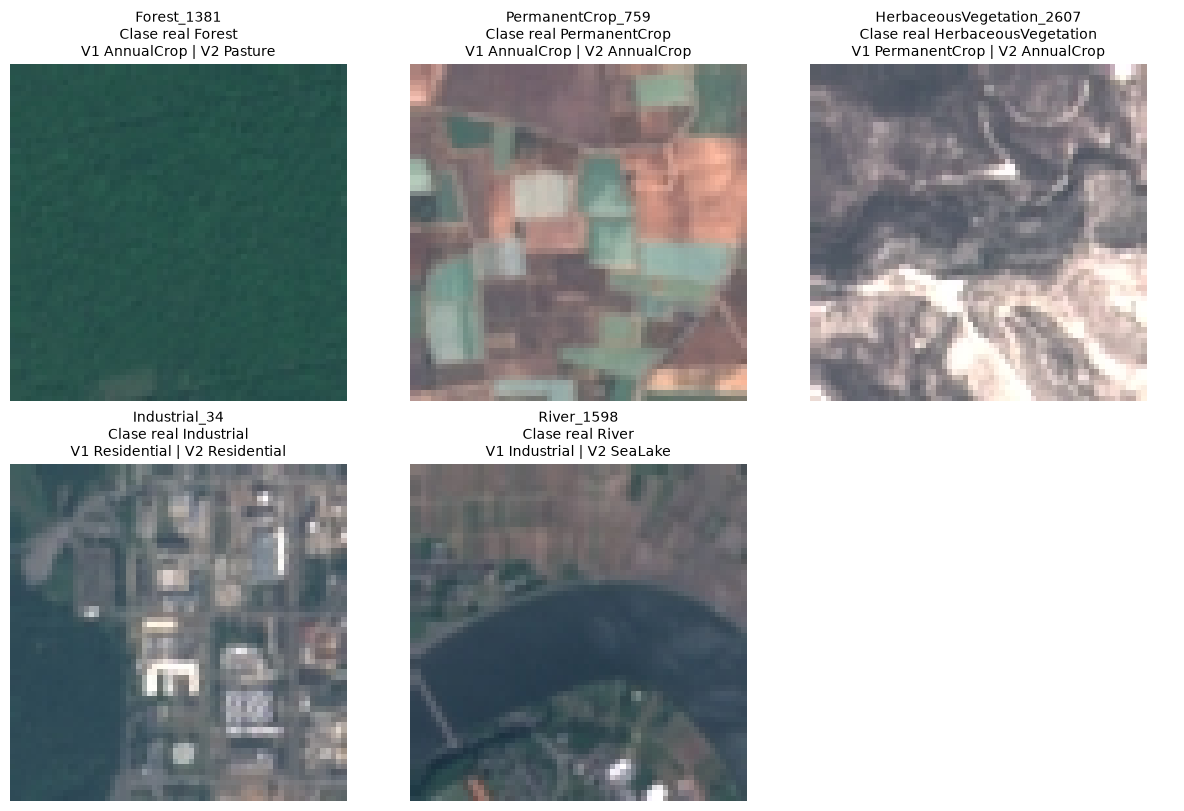

In [28]:
confusion_pairs = [
    ("Forest", "Pasture"),
    ("PermanentCrop", "AnnualCrop"),
    ("HerbaceousVegetation", "AnnualCrop"),
    ("Industrial", "Residential"),
    ("River", "SeaLake"),
]

selected_errors = []

for true_class, predicted_class in confusion_pairs:
    candidates = predictions[
        (predictions["class_name"] == true_class)
        & (predictions["pred_v2"] == predicted_class)
    ]
    selected_errors.append(candidates.sample(n=1, random_state=42))

error_examples = pd.concat(selected_errors, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(axes.flat, error_examples.itertuples(index=False)):
    image_path = RGB_DIR / row.class_name / f"{row.patch_id}.jpg"

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row.patch_id}\n"
        f"Clase real {row.class_name}\n"
        f"V1 {row.pred_v1} | V2 {row.pred_v2}",
        fontsize=10,
    )

plt.show()

En **Forest_1381** vemos una superficie verde bastante uniforme en la que apenas se distinguen las copas individuales. A la resolución de estos parches, esa continuidad puede recordar a un pasto y ofrece una posible explicación de la predicción **Pasture** de V2.

En **PermanentCrop_759**, ambas versiones eligen **AnnualCrop**, posiblemente porque el mosaico de parcelas rectangulares verdes y marrones recuerda a un conjunto de campos de cultivo anual y las hileras apenas se aprecian. V2 también elige **AnnualCrop** en **HerbaceousVegetation_2607**, donde las zonas claras y oscuras pueden parecer la mezcla de vegetación y suelo expuesto de su descripción.

En **Industrial_34**, las dos versiones predicen **Residential**. Vemos tejados y vías entre edificios, pero cuesta apreciar el tamaño de las construcciones en el recorte, un rasgo que ayudaría a distinguir las naves de las viviendas. En **River_1598**, V2 predice **SeaLake**, lo que podría deberse a que el agua domina la imagen y solo vemos una parte de la curva, parecida a la orilla de un lago.


### Revisión de las descripciones visuales

Al comparar V1 con la V2 original vimos que para algunas clases obteníamos más aciertos con el nombre. Por eso, después de revisar las descripciones visuales de V2, probamos por separado recuperar los nombres de **Forest** y **AnnualCrop**. En cada prueba cambiamos una sola frase y volvimos a evaluar los diez prompts juntos para ver qué pasaba tanto en la clase que habíamos cambiado como en el conjunto de 8.000 parches.


In [29]:
phrases_v2_revised = {
    "AnnualCrop": "rectangular fields with low crops and patches of bare soil",
    "Forest": "a forest",
    "HerbaceousVegetation": "open ground with irregular patches of low wild vegetation",
    "Highway": "a broad paved highway with parallel lanes running across the landscape",
    "Industrial": "large rectangular factory roofs with wide service roads and paved loading areas",
    "Pasture": "an open grazing field with short, even grass and distinct field boundaries",
    "PermanentCrop": "an orchard with evenly spaced tree crowns or a vineyard with parallel rows of vines",
    "Residential": "a neighborhood with closely spaced houses along small streets",
    "River": "a continuous band of water curving between two banks across the landscape",
    "SeaLake": "a wide, uninterrupted expanse of open water with a mostly uniform surface",
}


In [30]:
versions = {
    "V2 original": class_phrases_v2,
    "V2 revisada": phrases_v2_revised,
}

class_labels = np.asarray(class_names)
predictions_v2 = clip_index[["patch_id", "class_name"]].copy()
correct_by_version = pd.DataFrame(index=clip_index.index)

for version, phrases in versions.items():
    prompts = [
        f"a satellite photo of {phrases[class_name]}"
        for class_name in class_names
    ]

    text_embeddings = encode_prompts(prompts)
    scores = clip_embeddings @ text_embeddings.T

    predictions_v2[version] = class_labels[scores.argmax(axis=1)]
    correct_by_version[version] = predictions_v2[version].eq(
        predictions_v2["class_name"]
    )

comparison = (
    correct_by_version.groupby(predictions_v2["class_name"])
    .mean()
    .reindex(class_names)
    .mul(100)
)

comparison.loc["Global"] = correct_by_version.mean().mul(100)
comparison["Cambio (pp)"] = comparison["V2 revisada"] - comparison["V2 original"]

display(comparison.round(2))

,V2 original,V2 revisada,Cambio (pp)
class_name,,,
AnnualCrop,79.75,73.12,-6.62
Forest,2.38,53.75,51.38
HerbaceousVegetation,2.38,12.62,10.25
Highway,52.75,51.88,-0.87
Industrial,71.12,77.75,6.62
Pasture,29.75,26.38,-3.38
PermanentCrop,8.12,11.25,3.12
Residential,92.88,91.50,-1.38
River,40.62,40.00,-0.62


Al sustituir únicamente la descripción de **Forest** por *a forest* dentro del conjunto revisado, los aciertos en los bosques pasaron del 18,25 % al 53,75 % y la exactitud global subió del 49,19 % al 52,60 %. Una explicación posible es que el nombre de la clase abarque recortes más variados. En el ejemplo del mosaico, las copas apenas se distinguen y la textura moteada de la descripción es difícil de apreciar.

También probamos *annual crop fields* para **AnnualCrop** sobre el conjunto con el nombre de **Forest**. Los aciertos en cultivos anuales subieron del 73,1 % al 96,1 %, pero la exactitud global bajó del 52,60 % al 46,20 %. Como queríamos mejorar el conjunto completo, mantuvimos la descripción visual de **AnnualCrop** y dejamos **Forest** como la única clase de V2 revisada que usa el nombre de V1.

En la comparación de la tabla, la V2 final alcanza el **52,60 %** frente al **45,62 %** de la V2 original, con **558 aciertos adicionales**. En **Forest** pasamos del 2,38 % al 53,75 %, una diferencia de **51,38 puntos porcentuales** respecto a la V2 original.


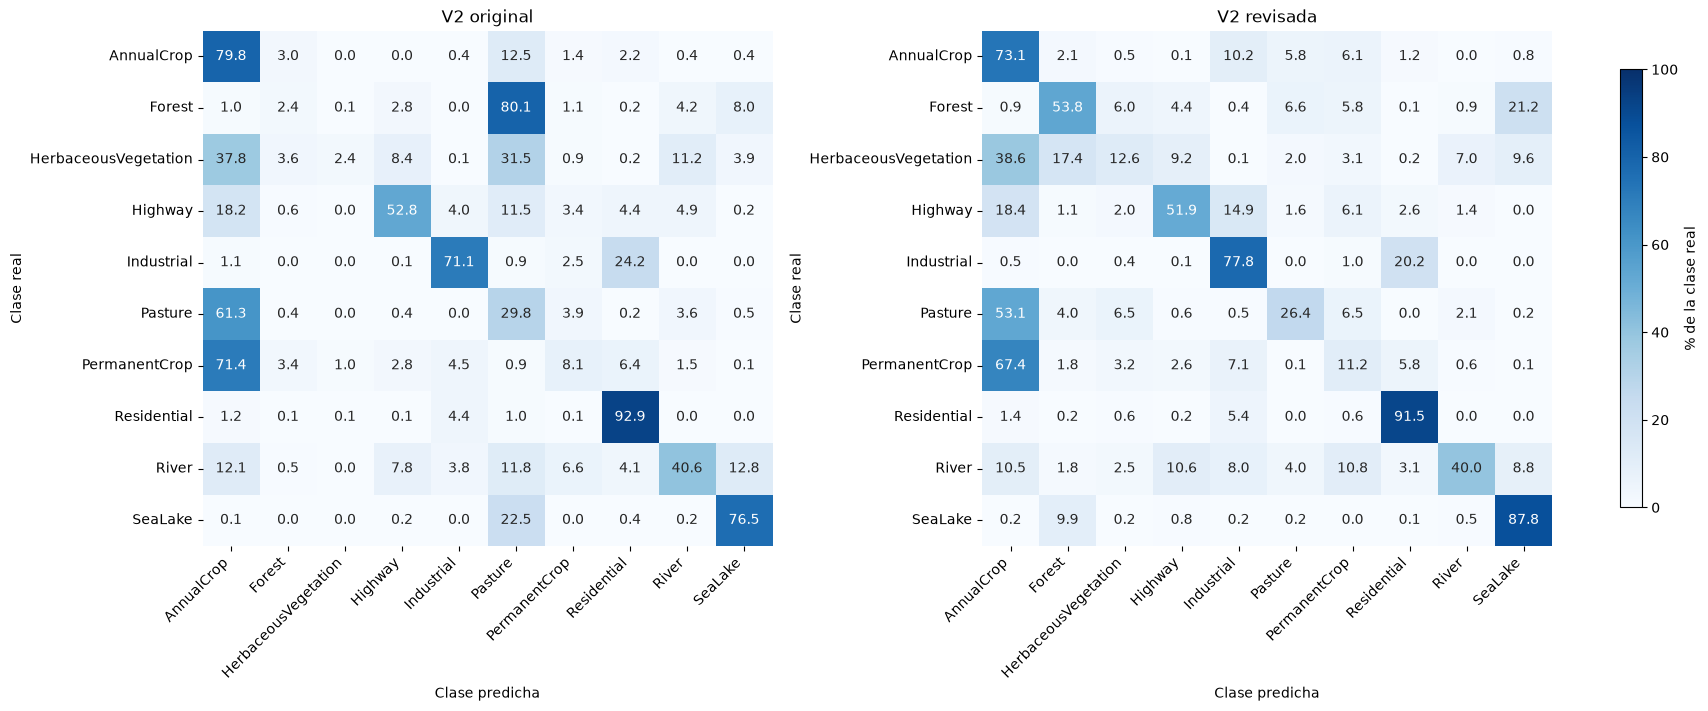

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout="constrained")

for ax, version in zip(axes, ["V2 original", "V2 revisada"]):
    matrix = confusion_matrix(
        predictions_v2["class_name"],
        predictions_v2[version],
        labels=class_names,
        normalize="true",
    ) * 100

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax,
    )

    ax.set(title=version, xlabel="Clase predicha", ylabel="Clase real")
    ax.tick_params(axis="y", labelrotation=0)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.colorbar(
    axes[0].collections[0],
    ax=axes,
    label="% de la clase real",
    shrink=0.85,
)

plt.show()

### Conclusión

En la matriz final vemos que la proporción de bosques etiquetados como **Pasture** baja del 80,1 % al 6,6 %, mientras que un 21,25 % se clasifica como **SeaLake**. Estos resultados nos ayudaron a elegir la redacción según el efecto de cada frase sobre todas las clases, ya que una mejora en una clase puede ir acompañada de más fallos en otras. Como ajustamos los prompts después de examinar estos mismos parches, interpretamos los resultados como exploratorios dentro de nuestro subconjunto.

En el apartado C pasamos a estudiar cómo se agrupan los parches a partir de las características extraídas en A y utilizamos las etiquetas de EuroSAT para evaluar los grupos una vez formados.


## Apartado C. Agrupamiento sin etiquetas e índice FAISS

En este apartado comprobamos si los parches se organizan por sí solos en grupos parecidos a las diez clases de EuroSAT. Agrupamos cada espacio de características del apartado A con **k-means** (sin usar las etiquetas) y después evaluamos los grupos con la **silueta** y el **ARI**. Como referencia supervisada, clasificamos los parches con **kNN** sobre un índice **FAISS** y comparamos el tiempo de consulta con el de una búsqueda exhaustiva. Por último, dibujamos un mapa **t-SNE** y revisamos qué grupos forma la máquina que no coinciden con las etiquetas oficiales.

### Matrices de características

Vamos a comparar seis espacios de color: los momentos de color, Haralick, LBP, la unión de los tres descriptores clásicos y los embeddings de ResNet50 y CLIP. Ordenamos todas las filas, de modo que la fila *i* corresponde al mismo parche en todos los espacios.

Los descriptores clásicos mezclan magnitudes con escalas muy distintas. Por ejemplo, la media del canal rojo va de 0 a 255 y la homogeneidad de Haralick de 0 a 1. Por eso los estandarizamos antes de medir distancias. Los embeddings de ResNet50 los normalizamos a longitud uno, como ya hicimos con CLIP, para que la distancia euclídea entre dos parches dependa del ángulo entre sus vectores y no de su longitud.

In [45]:
from sklearn.preprocessing import StandardScaler, normalize

key_columns = ["class_name", "patch_id"]


def align_features(features):
    aligned = clip_index.merge(features, on=key_columns, how="left", validate="one_to_one")
    values = aligned.drop(columns=key_columns).to_numpy(dtype=np.float64)
    return values


color_values = align_features(spectral_features)
haralick_values = align_features(haralick_features)
lbp_values = align_features(lbp_features)

feature_spaces = {
    "Momentos de color": color_values,
    "Haralick": haralick_values,
    "LBP": lbp_values,
    "Color + textura": np.hstack([color_values, haralick_values, lbp_values]),
    "ResNet50": normalize(resnet50_embeddings),
    "CLIP": clip_embeddings,
}
classical_spaces = ["Momentos de color", "Haralick", "LBP", "Color + textura"]
true_labels = clip_index["class_name"].to_numpy()

for name, values in feature_spaces.items():
    print(f"{name:18} → {values.shape}")

Momentos de color  → (8000, 36)
Haralick           → (8000, 15)
LBP                → (8000, 10)
Color + textura    → (8000, 61)
ResNet50           → (8000, 2048)
CLIP               → (8000, 512)


### k-means con diez grupos

Pedimos a k-means tantos grupos como clases oficiales, diez, y repetimos la inicialización diez veces con una semilla fija. Evaluamos cada agrupamiento con dos medidas:

- **Silueta**: compara, para cada parche, la distancia media a los parches de su grupo con la distancia media al grupo vecino más cercano. Va de −1 a 1 y no usa las etiquetas, así que mide si los grupos están compactos y separados en ese espacio.
- **ARI** (*Adjusted Rand Index*): mide cuánto coinciden los grupos con las clases reales, descontando las coincidencias que aparecerían por azar. Vale 0 para un reparto aleatorio y 1 si los grupos reproducen exactamente las clases.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

n_clusters = len(class_names)
cluster_labels = {}
clustering_rows = []

for name, values in feature_spaces.items():
    if name in classical_spaces:
        values = StandardScaler().fit_transform(values)
    values = values.astype(np.float32)

    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
    labels = kmeans.fit_predict(values)
    cluster_labels[name] = labels

    clustering_rows.append({
        "Descriptor": name,
        "Dimensiones": values.shape[1],
        "Silueta": silhouette_score(values, labels),
        "ARI": adjusted_rand_score(true_labels, labels),
    })

clustering_results = pd.DataFrame(clustering_rows).set_index("Descriptor")
display(clustering_results.round(3))

,Dimensiones,Silueta,ARI
Descriptor,,,
Momentos de color,36,0.170,0.204
Haralick,15,0.328,0.276
LBP,10,0.194,0.327
Color + textura,61,0.167,0.340
ResNet50,2048,0.104,0.538
CLIP,512,0.115,0.450


Según los resultados, ningún espacio forma grupos muy separados. La silueta más alta es 0,328, con Haralick, y la de los embeddings ronda tan solo 0,10. Cabe destacar que la silueta y el ARI ordenan los descriptores casi al revés. Haralick produce los grupos más compactos, pero su ARI es solo 0,276, por lo que agrupa los parches por su nivel de contraste y homogeneidad, una propiedad que comparten usos del suelo distintos. ResNet50 tiene la silueta más baja, 0,104, y el ARI más alto, **0,538**, seguido de CLIP con 0,450. En sus espacios no aparecen fronteras claras, pero los grupos que encuentra k-means se parecen más a las clases oficiales.

Entre los descriptores clásicos, unir color y textura da el mejor ARI (0,340), algo por encima de solo LBP (0,327). Los momentos de color, con 0,204, son los que peor reproducen las clases.

### kNN con FAISS como referencia supervisada

Para saber hasta dónde podrían llegar estas características si conociéramos las etiquetas, separamos de forma estratificada un 80 % de los parches como referencia y un 20 % como consulta, con la misma semilla. Cada parche de consulta recibe la clase mayoritaria entre sus **5 vecinos más cercanos** del conjunto de referencia. En caso de empate, gana la clase del vecino más próximo. En los descriptores clásicos ajustamos la estandarización solo con los parches de referencia.

Buscamos los vecinos con dos índices de FAISS:

- **IndexFlatL2**: búsqueda exhaustiva. Calcula la distancia a los 6.400 parches de referencia y devuelve los vecinos exactos.
- **IndexIVFFlat**: búsqueda aproximada. Reparte los parches de referencia en 64 celdas con k-means y, en cada consulta, solo recorre las 4 celdas cuyo centro está más cerca.

Lanzamos las consultas de una en una para medir el tiempo medio por consulta. También calculamos qué porcentaje de los vecinos exactos recupera el índice aproximado.

In [ ]:
import time
from collections import Counter

import faiss
from sklearn.model_selection import train_test_split

faiss.omp_set_num_threads(1)

train_rows, test_rows = train_test_split(
    np.arange(len(true_labels)),
    test_size=0.2,
    stratify=true_labels,
    random_state=42,
)
train_labels = true_labels[train_rows]
test_labels = true_labels[test_rows]

n_neighbors = 5
n_lists = 64
n_probe = 4


def search_one_by_one(index, queries):
    neighbor_ids = []
    start = time.perf_counter()

    for query in queries:
        _, ids = index.search(query[None, :], n_neighbors)
        neighbor_ids.append(ids[0])

    elapsed = time.perf_counter() - start
    return np.vstack(neighbor_ids), 1000 * elapsed / len(queries)


def majority_vote(neighbor_ids):
    # Counter conserva el orden de aparición, así que un empate lo gana el vecino más cercano
    return np.array([
        Counter(train_labels[ids]).most_common(1)[0][0] for ids in neighbor_ids
    ])


print("Parches de referencia:", len(train_rows))
print("Parches de consulta:", len(test_rows))

Parches de referencia: 6400
Parches de consulta: 1600


In [35]:
knn_rows = []

for name, values in feature_spaces.items():
    if name in classical_spaces:
        scaler = StandardScaler().fit(values[train_rows])
        values = scaler.transform(values)

    values = np.ascontiguousarray(values, dtype=np.float32)
    train_values, test_values = values[train_rows], values[test_rows]
    dimensions = values.shape[1]

    exact_index = faiss.IndexFlatL2(dimensions)
    exact_index.add(train_values)

    quantizer = faiss.IndexFlatL2(dimensions)
    ivf_index = faiss.IndexIVFFlat(quantizer, dimensions, n_lists)
    ivf_index.train(train_values)
    ivf_index.add(train_values)
    ivf_index.nprobe = n_probe

    exact_ids, exact_ms = search_one_by_one(exact_index, test_values)
    ivf_ids, ivf_ms = search_one_by_one(ivf_index, test_values)

    shared_neighbors = np.mean([
        len(set(exact) & set(approximate)) / n_neighbors
        for exact, approximate in zip(exact_ids, ivf_ids)
    ])

    knn_rows.append({
        "Descriptor": name,
        "Exactitud exhaustiva (%)": 100 * np.mean(majority_vote(exact_ids) == test_labels),
        "Exactitud IVF (%)": 100 * np.mean(majority_vote(ivf_ids) == test_labels),
        "Vecinos exactos recuperados (%)": 100 * shared_neighbors,
        "ms por consulta exhaustiva": exact_ms,
        "ms por consulta IVF": ivf_ms,
        "Aceleración": exact_ms / ivf_ms,
    })

knn_results = pd.DataFrame(knn_rows).set_index("Descriptor")
display(knn_results.round(3))

,Exactitud exhaustiva (%),Exactitud IVF (%),Vecinos exactos recuperados (%),ms por consulta exhaustiva,ms por consulta IVF,Aceleración
Descriptor,,,,,,
Momentos de color,74.188,73.562,97.638,0.019,0.005,3.819
Haralick,68.188,68.188,99.875,0.030,0.005,6.208
LBP,69.312,68.562,97.312,0.020,0.004,4.481
Color + textura,85.125,84.750,97.562,0.041,0.007,5.664
ResNet50,90.688,90.625,91.300,0.785,0.066,11.861
CLIP,88.125,87.125,94.800,0.178,0.018,9.773


Con las etiquetas, todos los espacios mejoran mucho. ResNet50 clasifica bien el **90,69 %** de los parches de consulta y CLIP el 88,13 %. Entre los clásicos, la unión de color y textura llega al 85,13 %, más de diez puntos por encima del mejor descriptor por separado (momentos de color con un 74,19 %). Haralick y LBP se quedan en torno al 68–69 %. Por lo tanto, podemos afirmar que el color y la textura aportan información complementaria.

El índice IVF apenas cambia la exactitud, siendo la pérdida máxima de 1 punto (CLIP), pese a recuperar solo el 91,3 % de los vecinos exactos en ResNet50 y el 94,8 % en CLIP. Algunos vecinos cambian, pero suelen ser de la misma clase y la votación no se altera. La ganancia de tiempo depende de la dimensión. En nuestra ejecución, una consulta exhaustiva en ResNet50 tarda 3,9 ms y con IVF 0,32 ms, unas 12 veces menos. En CLIP la aceleración es de 13 veces. En los descriptores clásicos, de 10 a 61 dimensiones, la búsqueda exhaustiva ya tarda menos de 0,06 ms y el ahorro en valor absoluto es insignificante. Estos tiempos varían un poco entre ejecuciones y según el procesador.

### Tabla comparativa de descriptores

Reunimos en una sola tabla las métricas de los dos enfoques. Por un lado la silueta y el ARI de k-means, que agrupa sin etiquetas, y por otro la exactitud del kNN exhaustivo, que sí las usa. En la gráfica mostramos el ARI multiplicado por 100 junto a la exactitud del kNN para verlos en la misma escala.

,Dimensiones,Silueta,ARI,Exactitud exhaustiva (%),ms por consulta IVF
Descriptor,,,,,
Momentos de color,36,0.170,0.204,74.188,0.005
Haralick,15,0.328,0.276,68.188,0.005
LBP,10,0.194,0.327,69.312,0.004
Color + textura,61,0.167,0.340,85.125,0.007
ResNet50,2048,0.104,0.538,90.688,0.066
CLIP,512,0.115,0.450,88.125,0.018


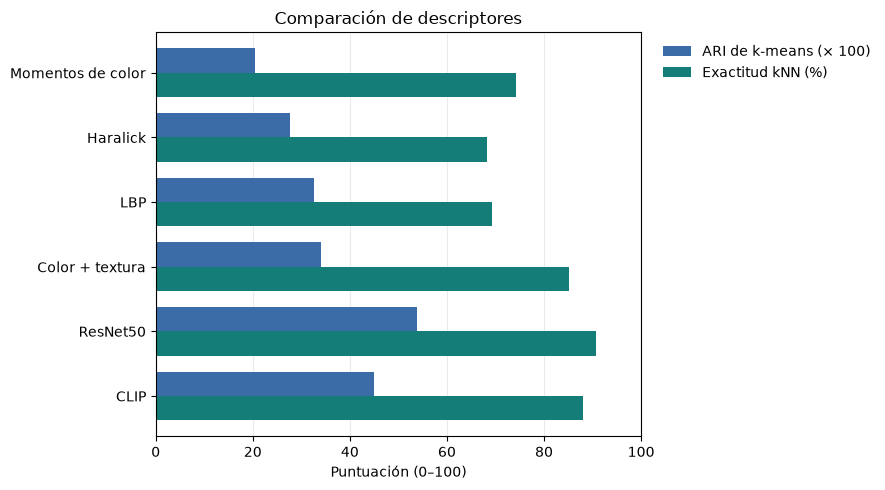

In [ ]:
descriptor_comparison = clustering_results.join(
    knn_results[["Exactitud exhaustiva (%)", "ms por consulta IVF"]]
)
display(descriptor_comparison.round(3))

chart_data = pd.DataFrame({
    "ARI de k-means (× 100)": 100 * descriptor_comparison["ARI"],
    "Exactitud kNN (%)": descriptor_comparison["Exactitud exhaustiva (%)"],
})

ax = chart_data.plot.barh(
    figsize=(9, 5),
    color=["#3B6CA8", "#147D78"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Comparación de descriptores")
ax.set_xlabel("Puntuación (0-100)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

plt.tight_layout()
plt.show()

**ResNet50 gana en las dos tareas**. Es el espacio en el que k-means se acerca más a las clases sin verlas (ARI 0,538) y el que mejor las separa cuando las conocemos (90,69 %). CLIP queda en segundo lugar en ambas. Nuestra hipótesis es que los embeddings resumen cómo se organizan los píxeles en el espacio, con bordes, formas y patrones repetidos, mientras que los momentos de color, Haralick y LBP describen estadísticas globales del parche.

La distancia entre las dos barras de cada descriptor indica cuánto se alejan las clases oficiales de los grupos naturales de cada espacio. Los momentos de color son el caso más claro, ya que con kNN superan a Haralick y a LBP, pero dan el peor ARI. Los vecinos más próximos en color suelen compartir clase, pero las grandes agrupaciones por color no coinciden con los usos del suelo.

### Mapa t-SNE de ResNet50

Para ver la estructura del espacio de ResNet50, lo proyectamos en dos dimensiones con t-SNE. Antes reducimos los 2.048 valores a 50 componentes principales con PCA para acelerar t-SNE y eliminar parte del ruido. Guardamos las coordenadas en `results/` para no repetir el cálculo.

Dibujamos el mismo mapa dos veces. A la izquierda coloreamos cada parche por su clase oficial y a la derecha por el grupo que le asignó k-means. t-SNE conserva sobre todo qué parches son vecinos, así que no interpretamos el tamaño de las islas ni la distancia entre islas lejanas.

In [37]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

tsne_path = features_dir / "tsne_resnet50.npy"

if tsne_path.is_file():
    tsne_coordinates = np.load(tsne_path)
    print("Coordenadas t-SNE cargadas desde results/.")
else:
    pca_values = PCA(n_components=50, random_state=42).fit_transform(feature_spaces["ResNet50"])
    tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)
    tsne_coordinates = tsne.fit_transform(pca_values)
    np.save(tsne_path, tsne_coordinates)

print("Dimensiones de las coordenadas t-SNE:", tsne_coordinates.shape)

Dimensiones de las coordenadas t-SNE: (8000, 2)


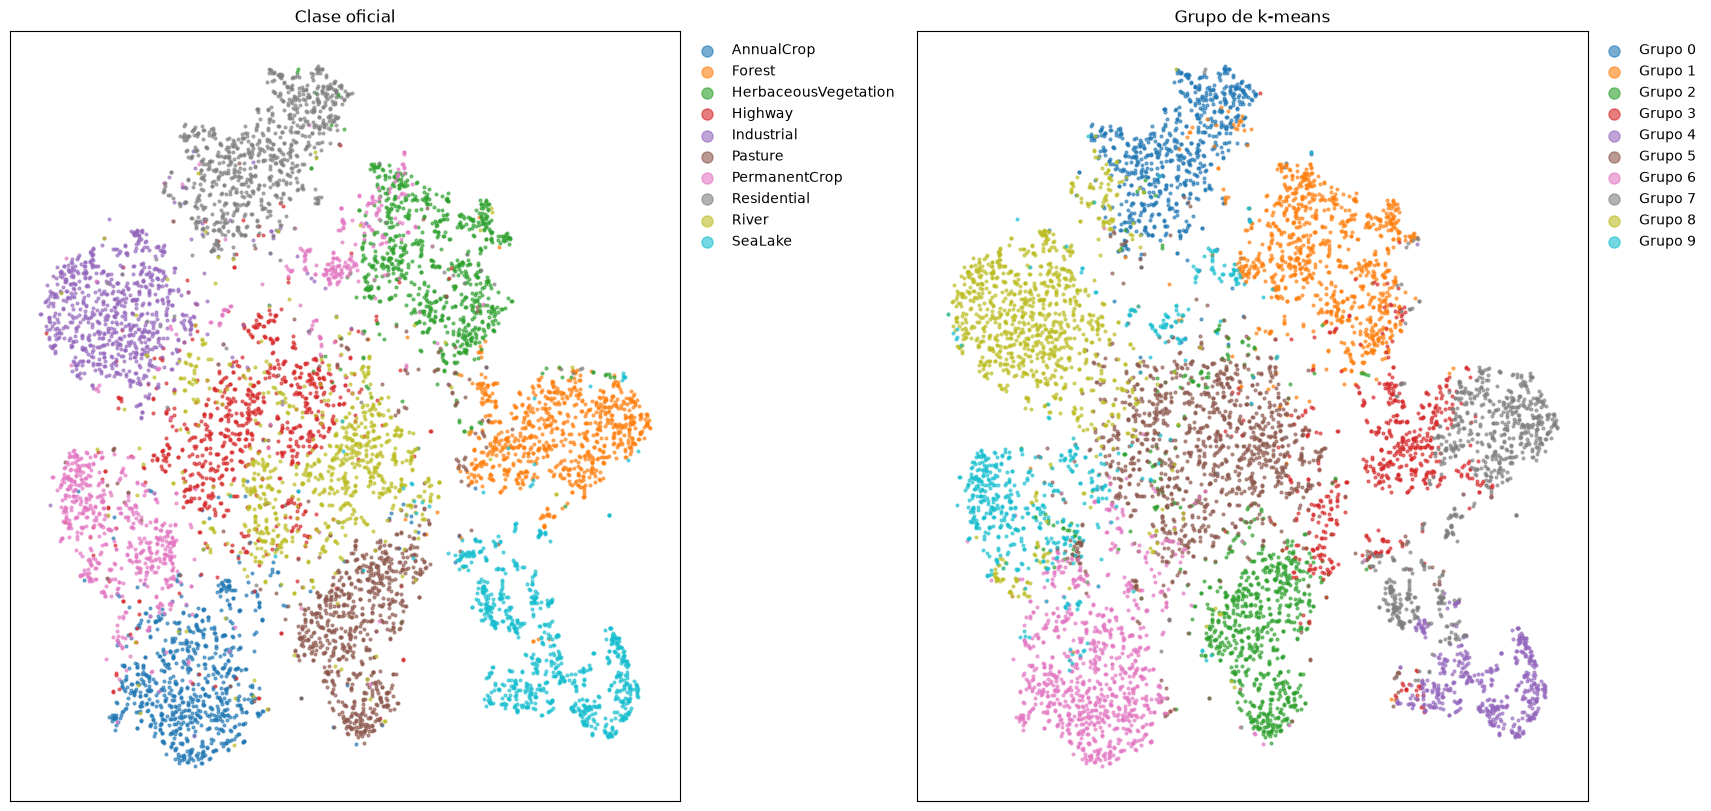

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), layout="constrained")
colors = plt.get_cmap("tab10")
resnet50_clusters = cluster_labels["ResNet50"]

for color_index, class_name in enumerate(class_names):
    mask = true_labels == class_name
    axes[0].scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        s=4,
        alpha=0.6,
        color=colors(color_index),
        label=class_name,
    )

for cluster in range(n_clusters):
    mask = resnet50_clusters == cluster
    axes[1].scatter(
        tsne_coordinates[mask, 0],
        tsne_coordinates[mask, 1],
        s=4,
        alpha=0.6,
        color=colors(cluster),
        label=f"Grupo {cluster}",
    )

for ax, title in zip(axes, ["Clase oficial", "Grupo de k-means"]):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1), markerscale=4, frameon=False)

plt.show()

En el mapa coloreado por clase aparecen islas bastante limpias para **Residential**, **Industrial**, **AnnualCrop**, **Pasture**, **HerbaceousVegetation**, **Forest** y **SeaLake**. **PermanentCrop** se reparte en varias zonas próximas a AnnualCrop, Industrial y HerbaceousVegetation. En el centro, **Highway** y **River** se entremezclan en una misma región.

El mapa coloreado por grupo reproduce gran parte de esas islas, lo que concuerda con el ARI de 0,538. Las diferencias aparecen en las mismas zonas. Un único grupo de k-means cubre la región central de Highway y River, y la isla de Forest y SeaLake se reparte entre grupos que no siguen la frontera entre bosque y agua.

### Grupos que no aparecen en las etiquetas

Para responder al reto cruzamos los grupos de k-means sobre ResNet50 con las clases oficiales. Cada fila es un grupo y cada celda cuenta cuántos de sus parches pertenecen a cada clase. Un grupo que coincide con una clase concentra casi toda su fila en una celda mientras que un grupo que la máquina "inventa" reparte su fila entre varias clases.

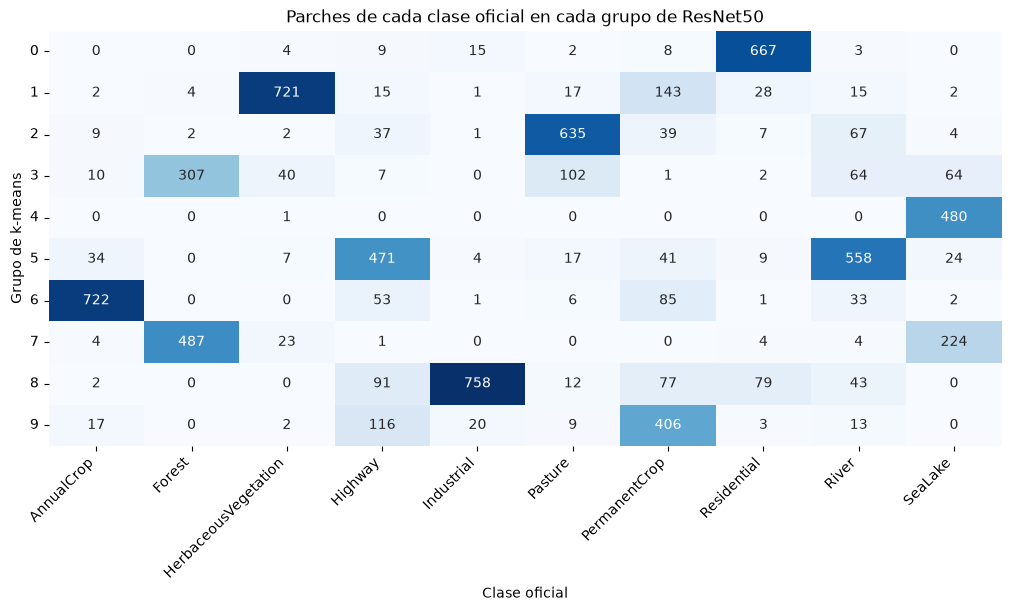

In [39]:
contingency = pd.crosstab(
    pd.Series(resnet50_clusters, name="Grupo de k-means"),
    pd.Series(true_labels, name="Clase oficial"),
).reindex(columns=class_names, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
sns.heatmap(
    contingency,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=ax,
)
ax.set_title("Parches de cada clase oficial en cada grupo de ResNet50")
ax.tick_params(axis="y", labelrotation=0)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

Consideramos que un grupo mezcla clases cuando su segunda clase más frecuente aporta al menos 100 parches, una octava parte de una clase. Aplicamos el mismo criterio a los grupos de CLIP para comprobar si las dos redes forman las mismas mezclas.

In [40]:
min_second_class = 100
mixed_rows = []

for name in ["ResNet50", "CLIP"]:
    table = pd.crosstab(cluster_labels[name], true_labels)

    for cluster, counts in table.iterrows():
        top_classes = counts.sort_values(ascending=False)

        if top_classes.iloc[1] >= min_second_class:
            mixed_rows.append({
                "Descriptor": name,
                "Grupo": cluster,
                "Parches del grupo": counts.sum(),
                "Clase principal": top_classes.index[0],
                "Parches de la principal": top_classes.iloc[0],
                "Segunda clase": top_classes.index[1],
                "Parches de la segunda": top_classes.iloc[1],
            })

mixed_clusters = pd.DataFrame(mixed_rows)
display(mixed_clusters)

,Descriptor,Grupo,Parches del grupo,Clase principal,Parches de la principal,Segunda clase,Parches de la segunda
0,ResNet50,1,948,HerbaceousVegetation,721,PermanentCrop,143
1,ResNet50,3,597,Forest,307,Pasture,102
2,ResNet50,5,1165,River,558,Highway,471
3,ResNet50,7,747,Forest,487,SeaLake,224
4,ResNet50,9,586,PermanentCrop,406,Highway,116
5,CLIP,0,746,AnnualCrop,297,PermanentCrop,150
6,CLIP,2,815,PermanentCrop,442,Highway,134
7,CLIP,4,853,SeaLake,638,Forest,200
8,CLIP,5,900,River,465,Highway,386
9,CLIP,8,989,Forest,524,HerbaceousVegetation,176


Mostramos seis parches elegidos al azar, con semilla fija, de las dos clases principales de cada grupo mezclado de ResNet50.

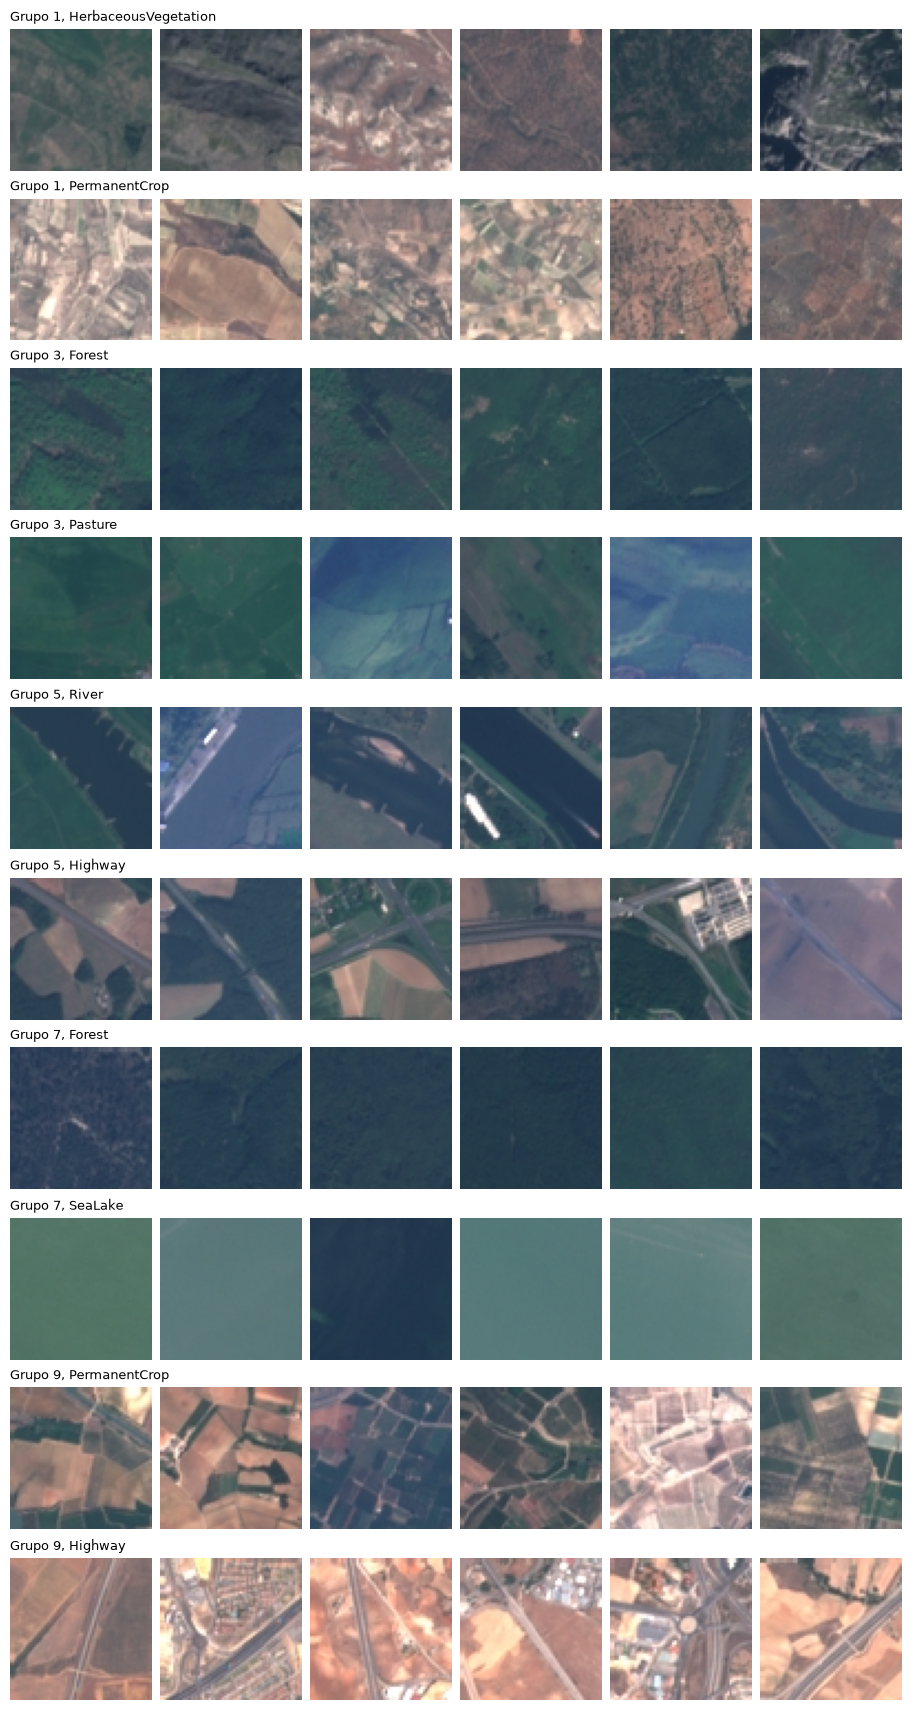

In [48]:
resnet50_mixed = mixed_clusters[mixed_clusters["Descriptor"] == "ResNet50"]
examples_per_class = 6

panel_rows = []
for _, row in resnet50_mixed.iterrows():
    panel_rows.append((row["Grupo"], row["Clase principal"]))
    panel_rows.append((row["Grupo"], row["Segunda clase"]))

fig, axes = plt.subplots(
    len(panel_rows), examples_per_class,
    figsize=(9, 1.7 * len(panel_rows)),
    layout="constrained",
)

for row_axes, (cluster, class_name) in zip(axes, panel_rows):
    candidates = clip_index[(resnet50_clusters == cluster) & (true_labels == class_name)]
    sample = candidates.sample(n=examples_per_class, random_state=42)

    for ax, patch in zip(row_axes, sample.itertuples(index=False)):
        with Image.open(RGB_DIR / patch.class_name / f"{patch.patch_id}.jpg") as image:
            ax.imshow(image.convert("RGB"))
        ax.axis("off")

    row_axes[0].set_title(f"Grupo {cluster}, {class_name}", fontsize=9, loc="left")

plt.show()

Los grupos mezclados no parecen errores aleatorios, ya que parches de grupos distintos comparten un rasgo visual que las etiquetas oficiales no recogen.

- **Corredores lineales.** El grupo más grande de ResNet50 reúne 558 parches de River y 471 de Highway. En casi todos vemos una franja alargada que cruza el parche, de agua o de asfalto, rodeada de campos o vegetación. CLIP forma el mismo grupo, con 465 parches de River y 386 de Highway. Las etiquetas distinguen el uso, transporte o agua, pero las dos redes se fijan en la geometría.
- **Superficies uniformes sin estructura.** Otro grupo junta 487 parches de Forest con 224 de SeaLake. Los bosques son copas oscuras y continuas, y los parches de agua son superficies turbias o verdosas sin orillas visibles. En ambos casos casi no hay bordes. CLIP también mezcla las dos clases, con 638 parches de SeaLake y 200 de Forest.
- **Dos tipos de agua.** Al mismo tiempo, ResNet50 aparta 480 parches de SeaLake en un grupo prácticamente puro de agua oscura y profunda. La máquina divide así la clase SeaLake en agua profunda y agua clara o turbia, y esta última se agrupa con el bosque.
- **Paisajes secos.** Dos grupos reúnen parches de tonos ocres y marrones de clases distintas. Uno junta 721 de HerbaceousVegetation, a menudo matorral en terreno montañoso, con 143 de PermanentCrop. Otro junta 406 de PermanentCrop con 116 de Highway, carreteras que cruzan campos secos. Una explicación posible es que la red agrupe por el clima o la región, como los paisajes mediterráneos, además de por el uso.
- **Vegetación verde con lindes.** Un grupo más pequeño reúne 307 parches de Forest y 102 de Pasture, superficies verdes oscuras atravesadas por caminos o límites de parcela.

### Conclusión

Un algoritmo sin etiquetas descubre buena parte de los usos del suelo, pero no todos. Con los embeddings de ResNet50, k-means encuentra grupos en los que domina claramente una sola clase para Residential, AnnualCrop, Industrial y el agua profunda, y alcanza un ARI de 0,538. La información para separar las diez clases está en las características, como muestra el 90,69 % del kNN, pero varias clases no forman grupos naturales en el espacio de la red.

La máquina organiza los parches por su aspecto visual y no por su función. Por eso inventa grupos que no existen en EuroSAT: corredores lineales de agua o asfalto, superficies uniformes sin bordes, paisajes secos de tonos ocres y vegetación con lindes. También divide SeaLake en agua profunda y agua turbia. Que ResNet50 y CLIP formen las dos primeras mezclas indica que no dependen de una red concreta.

Estos resultados dependen de haber fijado diez grupos y del subconjunto de 8.000 parches, así que los interpretamos como una exploración de cómo se estructuran los datos más que como una partición definitiva.